# Nordland EDA — preprocessing design

This notebook measures brightness and adjacent-frame change to identify unusable tunnel frames, a long stationary segment, clean moving frames, and an independent moving holdout.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

def frames(folder):
    items = {int(path.stem.rsplit('-', 1)[-1]): path for path in folder.glob('images-*.png')}
    if not items:
        raise FileNotFoundError(folder)
    return items

def frame_stats(paths):
    brightness = np.empty(len(paths), dtype=np.float32)
    changes = np.full(len(paths), np.nan, dtype=np.float32)
    previous = None
    for index, path in enumerate(paths):
        with Image.open(path) as image:
            gray = np.asarray(image.convert('L').resize((64, 36)), dtype=np.float32) / 255
        brightness[index] = gray.mean()
        if previous is not None:
            changes[index - 1] = np.abs(previous - gray).mean()
        previous = gray
    return brightness, changes

def segments(positions, mask, min_length=1):
    padded = np.r_[False, mask, False].astype(np.int8)
    starts = np.flatnonzero(np.diff(padded) == 1)
    stops = np.flatnonzero(np.diff(padded) == -1)
    return [(int(positions[a]), int(positions[b - 1]))
            for a, b in zip(starts, stops) if b - a >= min_length]

ROOT = Path.cwd()
if not (ROOT / 'data' / 'nordland-part-2020').is_dir():
    ROOT = ROOT.parent
DATA = ROOT / 'data' / 'nordland-part-2020'
DARK_THRESHOLD = 0.08
STILL_THRESHOLD = 0.004
ROLLING_WINDOW = 11
assert DATA.is_dir(), DATA
print('Dataset:', DATA)

Dataset: d:\AIO\Project\Nordland-Cross-Season-VPR\data\nordland-part-2020


## 1. Measure the route

Each image is converted to a 64×36 grayscale thumbnail. Brightness is its mean value; motion is the mean absolute difference from the next frame.

In [2]:
summer, winter = frames(DATA / 'summer'), frames(DATA / 'winter')
assert summer.keys() == winter.keys()
positions = np.array(sorted(summer))
assert np.array_equal(positions, np.arange(251, 2001))
summer_brightness, summer_diff = frame_stats([summer[int(p)] for p in positions])
winter_brightness, winter_diff = frame_stats([winter[int(p)] for p in positions])
motion = np.fmax(summer_diff, winter_diff)
smooth_motion = pd.Series(motion).rolling(ROLLING_WINDOW, center=True, min_periods=6).median().to_numpy()
stats = pd.DataFrame({
    'position': positions,
    'summer_brightness': summer_brightness,
    'winter_brightness': winter_brightness,
    'summer_next_diff': summer_diff,
    'winter_next_diff': winter_diff,
    'smoothed_motion': smooth_motion,
})
stats.describe().round(4)

,position,summer_brightness,winter_brightness,summer_next_diff,winter_next_diff,smoothed_motion
count,1750.0000,1750.0000,1750.0000,1749.0000,1749.0000,1749.0000
mean,1125.5000,0.3295,0.3865,0.0368,0.0447,0.0461
std,505.3258,0.0947,0.1065,0.0366,0.0421,0.0386
min,251.0000,0.0216,0.0248,0.0007,0.0000,0.0008
25%,688.2500,0.3228,0.3596,0.0012,0.0005,0.0011
50%,1125.5000,0.3665,0.4215,0.0317,0.0434,0.0493
75%,1562.7500,0.3691,0.4592,0.0577,0.0734,0.0784
max,2000.0000,0.4460,0.5422,0.2980,0.2226,0.1411


## 2. Evidence for the boundaries

,candidate,start,end
0,stationary core,1290,1792
1,tunnel,1872,2000


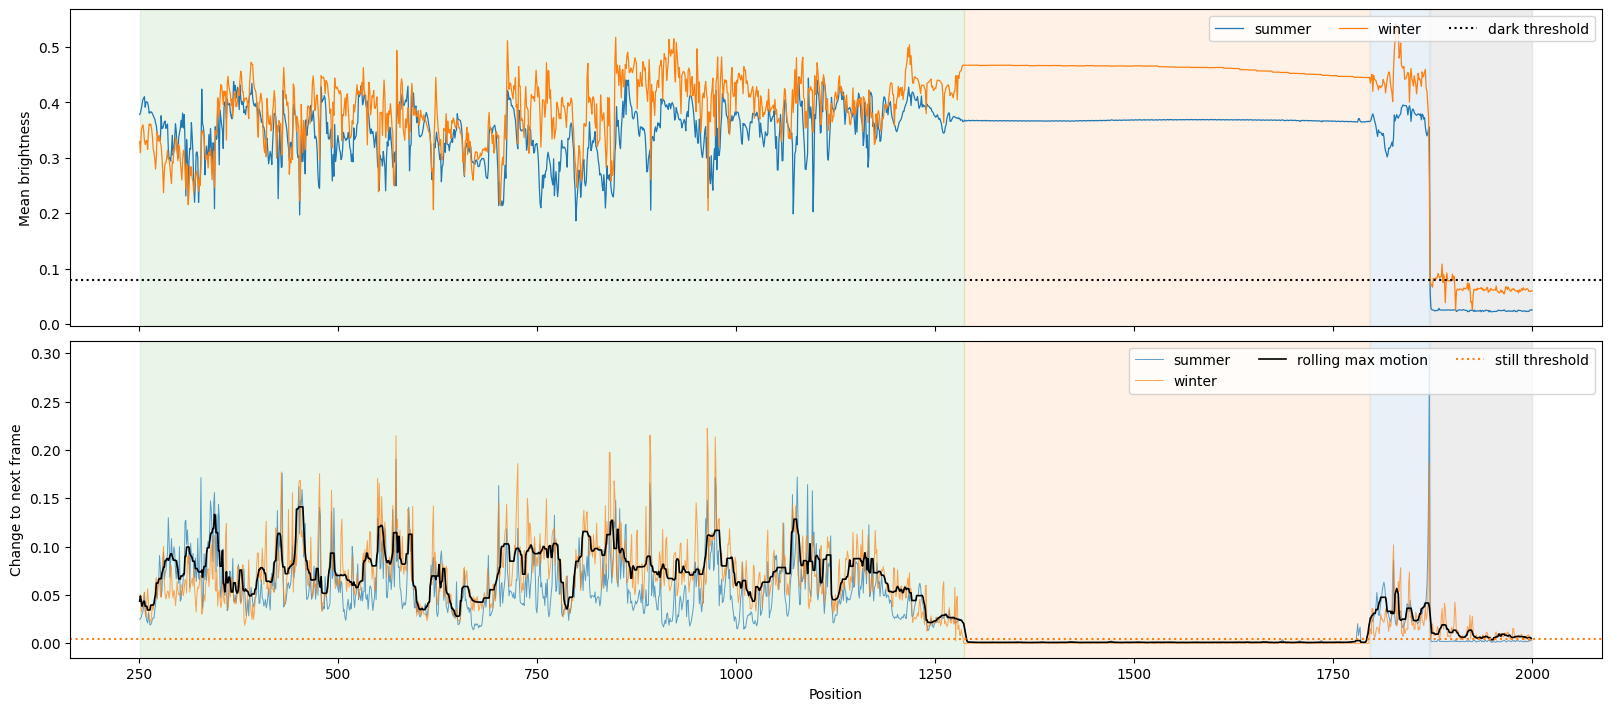

In [3]:
dark_mask = summer_brightness < DARK_THRESHOLD
still_core = smooth_motion < STILL_THRESHOLD
candidates = pd.DataFrame(
    [('stationary core', a, b) for a, b in segments(positions, still_core, min_length=10)]
    + [('tunnel', a, b) for a, b in segments(positions, dark_mask, min_length=10)],
    columns=['candidate', 'start', 'end'],
)
display(candidates)

regions = [
    ('clean train', 251, 1286, '#2ca02c'),
    ('stationary', 1287, 1795, '#ff7f0e'),
    ('moving holdout', 1796, 1871, '#1f77b4'),
    ('tunnel', 1872, 2000, '#555555'),
]
fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True, layout='constrained')
axes[0].plot(positions, summer_brightness, label='summer', linewidth=0.9)
axes[0].plot(positions, winter_brightness, label='winter', linewidth=0.9)
axes[0].axhline(DARK_THRESHOLD, color='black', linestyle=':', label='dark threshold')
axes[0].set_ylabel('Mean brightness')
axes[1].plot(positions, summer_diff, label='summer', linewidth=0.7, alpha=0.7)
axes[1].plot(positions, winter_diff, label='winter', linewidth=0.7, alpha=0.7)
axes[1].plot(positions, smooth_motion, label='rolling max motion', linewidth=1.2, color='black')
axes[1].axhline(STILL_THRESHOLD, color='#ff7f0e', linestyle=':', label='still threshold')
axes[1].set_ylabel('Change to next frame')
axes[1].set_xlabel('Position')
for ax in axes:
    for label, start, end, color in regions:
        ax.axvspan(start, end, color=color, alpha=0.10)
    ax.legend(loc='upper right', ncol=3)
plt.show()

The automatic stationary detector finds the stable core. Boundary inspection expands it to 1287–1795 so transition frames cannot become false negatives. Summer brightness detects the complete tunnel; requiring both seasons to be dark misses its entrance.

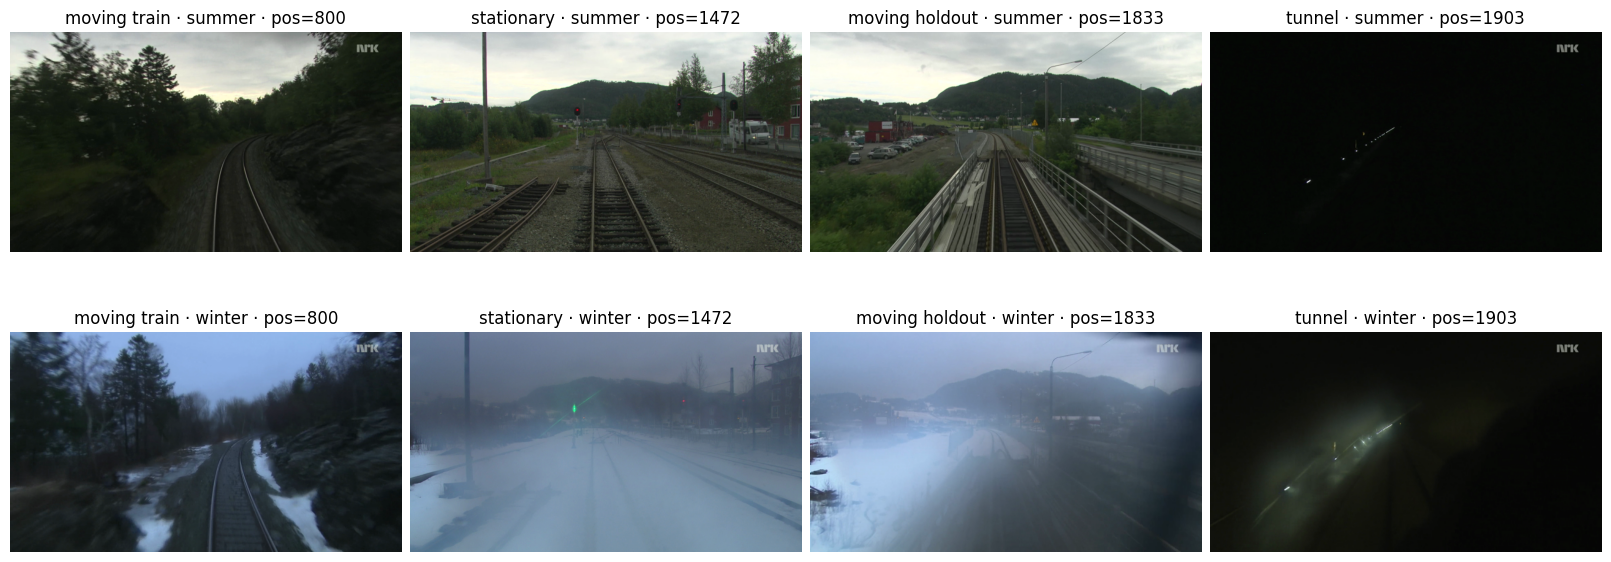

In [4]:
samples = [('moving train', 800), ('stationary', 1472), ('moving holdout', 1833), ('tunnel', 1903)]
fig, axes = plt.subplots(2, len(samples), figsize=(16, 6), layout='constrained')
for column, (label, position) in enumerate(samples):
    for row, (season, mapping) in enumerate([('summer', summer), ('winter', winter)]):
        with Image.open(mapping[position]) as image:
            axes[row, column].imshow(image.convert('RGB'))
        axes[row, column].set_title(f'{label} · {season} · pos={position}')
        axes[row, column].axis('off')
plt.show()

## 3. Preprocessing specification

In [5]:
stats['preprocessing_split'] = np.select(
    [stats.position.between(251, 1286),
     stats.position.between(1287, 1795),
     stats.position.between(1796, 1871),
     stats.position.between(1872, 2000)],
    ['train', 'stationary_excluded', 'validation', 'tunnel_excluded'],
    default='excluded',
)
summary = (stats.groupby('preprocessing_split').position
           .agg(start='min', end='max', frames='size').reset_index())
expected = {'train': 1036, 'stationary_excluded': 509, 'validation': 76, 'tunnel_excluded': 129}
assert stats.preprocessing_split.value_counts().to_dict() == expected
manifest_path = ROOT / 'data' / 'splits' / 'nordland_preprocessing.csv'
manifest_path.parent.mkdir(parents=True, exist_ok=True)
stats.to_csv(manifest_path, index=False)
display(summary)
print('Saved:', manifest_path)

,preprocessing_split,start,end,frames
0,stationary_excluded,1287,1795,509
1,train,251,1286,1036
2,tunnel_excluded,1872,2000,129
3,validation,1796,1871,76


Saved: d:\AIO\Project\Nordland-Cross-Season-VPR\data\splits\nordland_preprocessing.csv


In [6]:
def random_recall_at_1(database_size, radius=10):
    valid_pairs = database_size * (2 * radius + 1) - radius * (radius + 1)
    return 100 * valid_pairs / database_size ** 2

pd.DataFrame([
    {'evaluation': '4-fold validation', 'database': 259, 'random_R@1_%': random_recall_at_1(259)},
    {'evaluation': 'moving holdout', 'database': 76, 'random_R@1_%': random_recall_at_1(76)},
]).round(2)

,evaluation,database,random_R@1_%
0,4-fold validation,259,7.94
1,moving holdout,76,25.73


## Decision

- Train on positions **251–1286** where the train is moving and the scene is visible.
- Exclude **1287–1795**: nearly repeated stopped frames create false negatives.
- Use **1796–1871** only as an independent moving holdout.
- Exclude **1872–2000**: the summer sequence is inside a dark tunnel and lacks enough visual information for frame-level localization.
- Report 4-fold validation as the primary estimate; the 76-image holdout has a much higher random-hit baseline under the ±10 criterion.